# Chapter 5 - Estimating Demand

<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#5.2.2-Simulating-Demand" data-toc-modified-id="5.2.2-Simulating-Demand-1">5.2.2 Simulating Demand</a></span></li><li><span><a href="#5.2.3-Revealing-Demand" data-toc-modified-id="5.2.3-Revealing-Demand-2">5.2.3 Revealing Demand</a></span></li><li><span><a href="#5.3.2-Simulating-Discrete-Choice" data-toc-modified-id="5.3.2-Simulating-Discrete-Choice-3">5.3.2 Simulating Discrete Choice</a></span></li><li><span><a href="#5.4.1-Binomial-Likelihood" data-toc-modified-id="5.4.1-Binomial-Likelihood-4">5.4.1 Binomial Likelihood</a></span></li><li><span><a href="#5.4.2-Binomial-Likelihood-in-Python" data-toc-modified-id="5.4.2-Binomial-Likelihood-in-Python-5">5.4.2 Binomial Likelihood in Python</a></span></li><li><span><a href="#5.4.4-Maximum-Likelihood-OLS-in-Python" data-toc-modified-id="5.4.4-Maximum-Likelihood-OLS-in-Python-6">5.4.4 Maximum Likelihood OLS in Python</a></span></li><li><span><a href="#5.4.6-Probit-in-Python" data-toc-modified-id="5.4.6-Probit-in-Python-7">5.4.6 Probit in Python</a></span></li><li><span><a href="#5.4.7-Generalized-Linear-Model" data-toc-modified-id="5.4.7-Generalized-Linear-Model-8">5.4.7 Generalized Linear Model</a></span></li><li><span><a href="#5.5.3-Simulation-with-Probit-and-Logit-Estimators" data-toc-modified-id="5.5.3-Simulation-with-Probit-and-Logit-Estimators-9">5.5.3 Simulation with Probit and Logit Estimators</a></span></li><li><span><a href="#5.6.1-Multinomial-Choice-Model" data-toc-modified-id="5.6.1-Multinomial-Choice-Model-10">5.6.1 Multinomial Choice Model</a></span></li><li><span><a href="#5.6.3-Multinomial-Probit-in-Python" data-toc-modified-id="5.6.3-Multinomial-Probit-in-Python-11">5.6.3 Multinomial Probit in Python</a></span></li><li><span><a href="#5.6.5-Multinomial-Logit-in-Python" data-toc-modified-id="5.6.5-Multinomial-Logit-in-Python-12">5.6.5 Multinomial Logit in Python</a></span></li><li><span><a href="#5.6.6-Simulating-Multinomial-Choice" data-toc-modified-id="5.6.6-Simulating-Multinomial-Choice-13">5.6.6 Simulating Multinomial Choice</a></span></li><li><span><a href="#5.7.1-National-Household-Travel-Survey" data-toc-modified-id="5.7.1-National-Household-Travel-Survey-14">5.7.1 National Household Travel Survey</a></span></li><li><span><a href="#5.7.2-Demand-for-Cars" data-toc-modified-id="5.7.2-Demand-for-Cars-15">5.7.2 Demand for Cars</a></span></li><li><span><a href="#5.7.3-Estimating-Demand-for-Rail" data-toc-modified-id="5.7.3-Estimating-Demand-for-Rail-16">5.7.3 Estimating Demand for Rail</a></span></li><li><span><a href="#5.7.4-Predicting-Demand-for-Rail" data-toc-modified-id="5.7.4-Predicting-Demand-for-Rail-17">5.7.4 Predicting Demand for Rail</a></span></li></ul></div>

## 5.2.2 Simulating Demand

In [1]:
# as in the previous chapters, we use numpy
import numpy as np

In [2]:
# remove Python warnings
import warnings
warnings.filterwarnings("ignore")

In [3]:
# setting the seed in Numpy
# the random numbers of Python are not the ones of R,
# so our results are close to the book but not the same
np.random.seed(123456789)

N = 1000

# create a vector for the unobserved utility, u, from
# a normal distribution with a mean of 1 and a variance of 9
# loc is the mean and scale is the standard deviation (sd in R)
# np.sort puts the values from the smallest to the largest
u = np.sort(np.random.normal(loc=1, scale=3, size=N))

In [4]:
p = 2

# estimated probability
# u - p > 0 is a vector of True and False
# and its mean is the share of True
print(np.mean(u - p > 0))

0.366


In [5]:
# true probability
# pnorm in R is stats.norm.cdf in Python
from scipy import stats

print(1 - stats.norm.cdf(p, loc=1, scale=3))

0.36944134018176367


## 5.2.3 Revealing Demand

In [6]:
# 9 points between -10, 10.
p = np.random.uniform(low=-10, high=10, size=9)

# share of market buying A.
s = np.zeros(len(p))
for i in range(0, len(p)):
    s[i] = np.mean(u - p[i] > 0)

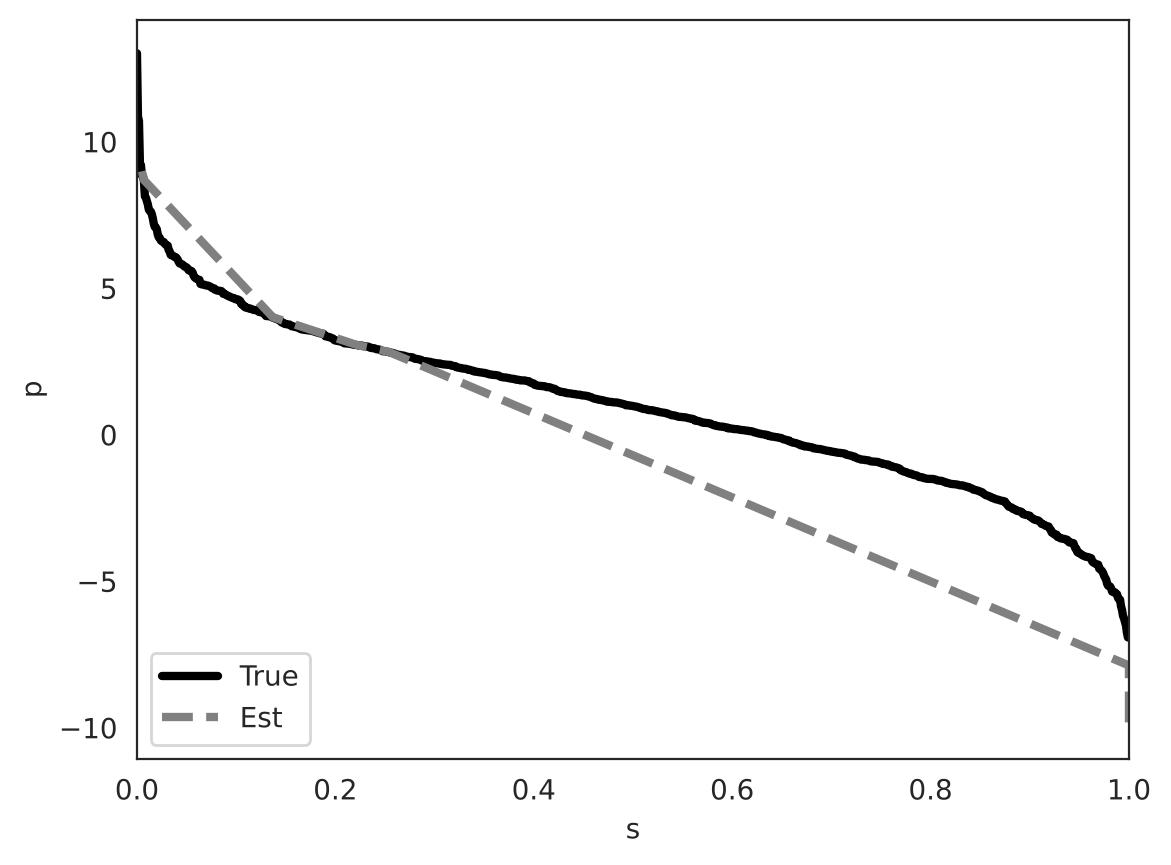

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# plotting with a R-looking plotting style
sns.set_style('white')

# ecdf(u)(u) in R presents the estimated probabilities of u.
# u is sorted, so the share of values below each u is 1/N, 2/N, ... up to 1
ecdf_u = np.arange(1, N+1)/N

# true demand: the share of people with u above the price
plt.plot(1 - ecdf_u, u, color='k', linewidth=3, label='True')

# estimated demand from the 9 prices
# np.argsort gives the positions which sort s (order in R)
plt.plot(np.sort(s), p[np.argsort(s)], color='grey', linewidth=3,
         linestyle='--', label='Est')

plt.xlabel('s')
plt.ylabel('p')
plt.xlim(0, 1)
plt.legend(loc='lower left')
plt.show()

## 5.3.2 Simulating Discrete Choice

In [8]:
np.random.seed(123456789)

N = 100
a = 2
b = -3
u = np.random.normal(size=N)
x = np.random.rand(N)

# the latent value, which we do not observe
ystar = a + b*x + u

# what we observe: y is 1 if ystar is above 0, and 0 if not
# in the book y is a vector of TRUE and FALSE
# statsmodels is not a big fan of boolean variables on the left of a formula
# so we code y in 0/1s
y = (ystar > 0).astype(int)

In [9]:
# using statsmodels and pandas, as in the previous chapters
import statsmodels.formula.api as sm
from statsmodels.iolib.summary2 import summary_col
import pandas as pd

# pack the variables in a dataframe
data = pd.DataFrame({'y': y, 'x': x})

lm1 = sm.ols(formula="y ~ x", data=data).fit()

In [10]:
# as in chapter 1, we create a function to plot a line
# from its slope and its intercept (abline in R)

def abline(slope, intercept, linestyle='-'):
    """Plot a linear function from slope and intercept"""
    axes = plt.gca()
    x_vals = np.array(axes.get_xlim())
    y_vals = intercept + slope * x_vals
    plt.plot(x_vals, y_vals, color='dimgray', linestyle=linestyle)

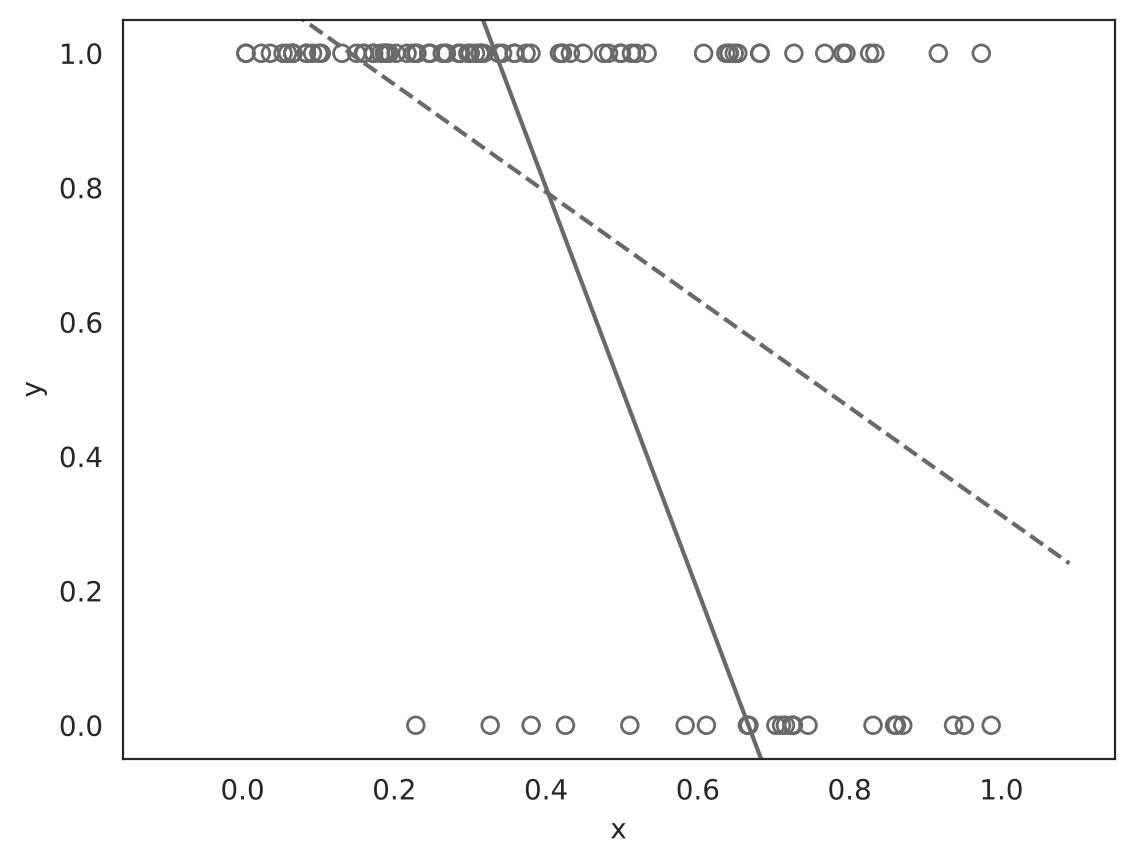

In [11]:
# plotting the dots
plt.scatter(x, y, facecolors='none', color='dimgray')

# the true relationship between ystar and x (solid line)
abline(intercept=a, slope=b)

# the relationship estimated by OLS (dashed line)
abline(intercept=lm1.params['Intercept'], slope=lm1.params['x'], linestyle='--')

plt.xlabel('x')
plt.ylabel('y')
# y is 0 or 1, so we keep the window between 0 and 1 as in the book
plt.ylim(-0.05, 1.05)
plt.show()

## 5.4.1 Binomial Likelihood

In [12]:
np.random.seed(123456789)

N = 100
p = 0.367 # the true probability of Head.
Head = np.random.rand(N) < p

# the observed frequency of Head.
print(np.mean(Head))

0.41


With the random numbers of R the book observes 34 Heads out of 100. The R code that follows is written with 34, so we keep 34 and our numbers can be compared with the book.

In [13]:
# R has factorial() and choose(), numpy does not
# so we write the two functions by hand

def factorial(n):
    """n factorial: 1 multiplied by 2, by 3, ... up to n"""
    # np.arange(1, n+1) gives the numbers 1, 2, ..., n
    # we ask for decimal numbers, because 100! is too big for the integers of numpy
    return np.prod(np.arange(1, n+1, dtype=float))

def choose(n, k):
    """Number of ways to pick k items among n (the coefficient of the binomial function)"""
    return factorial(n)/(factorial(k)*factorial(n-k))

In [14]:
# number of ways to get 3 Heads and 2 Tails
print(factorial(5)/(factorial(3)*factorial(2)))

10.0


In [15]:
# likelihood of 34 Heads and 66 Tails if the coin is fair
# in Python ** means "to the power of" (^ in R)
print(choose(100, 34)*(0.5**100))

0.00045810527728723993


## 5.4.2 Binomial Likelihood in Python

In [16]:
def ll_function(p, N, p_hat):
    "The objective function - minus the log likelihood of the coin"
    return -((p_hat*N)*np.log(p) + (1 - p_hat)*N*np.log(1-p))
    # the negative sign is there because minimize is a minimizer.

In [17]:
from scipy.optimize import minimize

# R has optimize() for a function of one parameter
# as in chapter 1, we use minimize() with bounds

# the minimize function needs an initial guess
x0 = 0.5
# we search between 0 and 1
# log(0) is minus infinity, so we stop just before 0 and just before 1
bounds = [(0.001, 0.999)]

# the values of N and p_hat are given to the function with args
a0 = minimize(ll_function, x0, args=(100, 0.34), bounds=bounds)

# the estimated probability ($minimum in R)
print(a0.x)
# the value of the function at this point ($objective in R)
print(a0.fun)

[0.33999999]
64.10354778811556


In [18]:
p = np.arange(1, 1001)/1000

# numpy computes on the whole vector p at once,
# so we do not need sapply as in R
# lchoose(100,34) in R is the log of choose(100,34)
log_lik = np.log(choose(100, 34)) + 34*np.log(p) + 66*np.log(1-p)

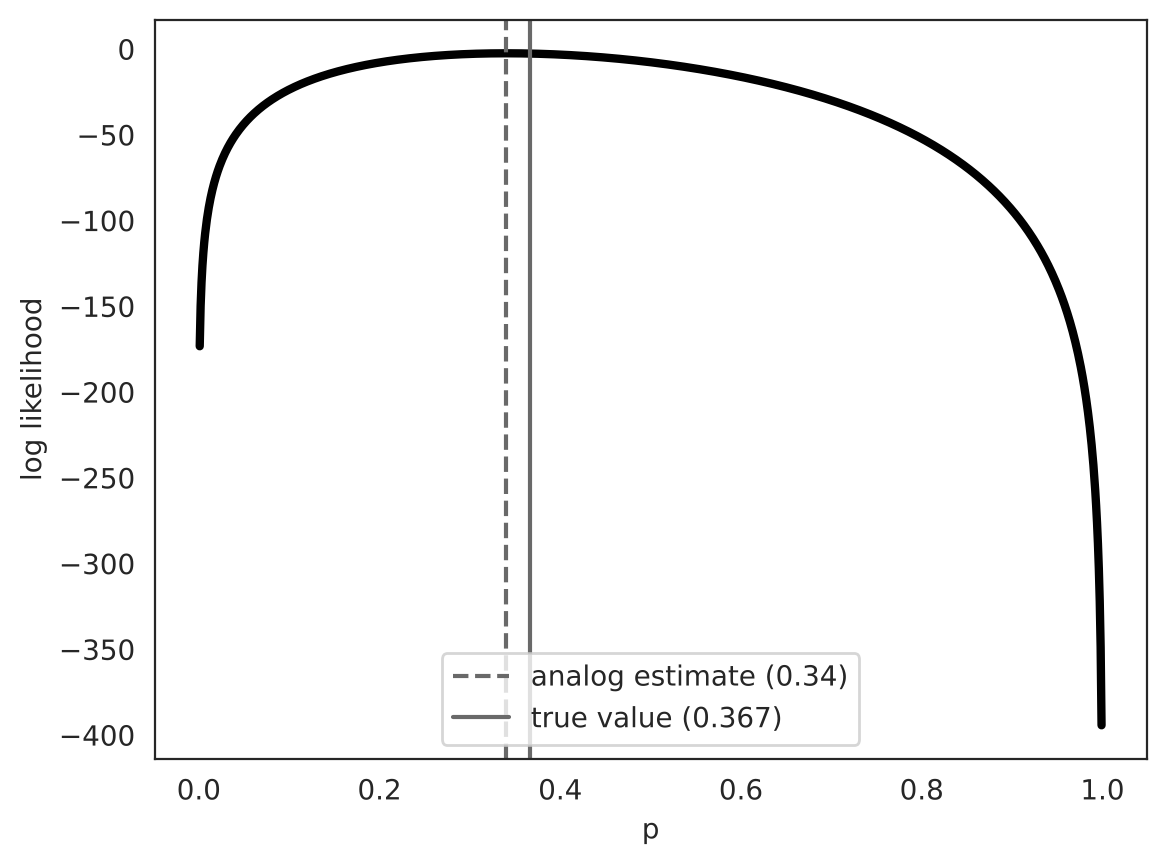

In [19]:
# the last value of p is 1, where the log likelihood is minus infinity
# matplotlib leaves this point out
plt.plot(p, log_lik, color='k', linewidth=3)

# lines at the analog estimate of 0.34 and at the true value of 0.367
plt.axvline(0.34, color='dimgray', linestyle='--', label='analog estimate (0.34)')
plt.axvline(0.367, color='dimgray', label='true value (0.367)')

plt.xlabel('p')
plt.ylabel('log likelihood')
plt.legend(loc='lower center')
plt.show()

## 5.4.4 Maximum Likelihood OLS in Python

In [20]:
def f_ols(para, y, X):
    """
    Minus the log likelihood of the OLS model
    * para: the log of sigma first, then the betas
    * y: the outcome
    * X: the explanatory variables, without the column of 1's
    """
    N = len(y)
    X = np.c_[np.ones(N), X]  # adds a column of 1's to the matrix
    J = X.shape[1]  # number of columns of X
    sig = np.exp(para[0])
    # sig must be positive.
    # The exponential function maps
    # from any real number to positive numbers.
    # It allows the optimizer to choose any value and
    # transforms that number into a positive value.
    beta = para[1:(J+1)]  # python starts counting at 0
    z = (y - X.dot(beta))/sig
    # dnorm in R is stats.norm.pdf in Python
    log_lik = -np.sum(np.log(stats.norm.pdf(z)) - np.log(sig))
    return log_lik
    # remember we are minimizing.

In [21]:
# optim in R is minimize in Python
# minimize takes in the function, then the starting values with x0,
# and then the values that the function needs with args
# Nelder-Mead is the default method of optim in R, here we have to ask for it
# we cheat by having it start at the true values.
a1 = minimize(f_ols, x0=[0, 2, -3], args=(ystar, x), method='Nelder-Mead')

# sig
# the estimates are in .x ($par in R)
print(np.exp(a1.x[0]))

0.9428055559456401


In [22]:
# beta
a1.x[1:3]

array([ 1.93139613, -2.56848077])

## 5.4.6 Probit in Python

In [23]:
def f_probit(beta, y, X):
    """Minus the log likelihood of the probit model"""
    X = np.c_[np.ones(len(y)), X]
    Xb = X.dot(beta)
    # pnorm in R is stats.norm.cdf in Python
    log_lik = (1 - y)*np.log(stats.norm.cdf(-Xb)) + y*np.log(stats.norm.cdf(Xb))
    return -np.sum(log_lik)

In [24]:
# the starting values are the OLS coefficients
minimize(f_probit, x0=lm1.params, args=(y, x), method='Nelder-Mead').x

array([ 2.36671203, -3.18118431])

## 5.4.7 Generalized Linear Model

In [25]:
# glm with a probit link in R is sm.probit in statsmodels
# disp=0 hides the message of the optimizer
sm.probit(formula="y ~ x", data=data).fit(disp=0).params

Intercept    2.366731
x           -3.181206
dtype: float64

## 5.5.3 Simulation with Probit and Logit Estimators

In [26]:
np.random.seed(123456789)

N = 5000

# creates two product characteristic matrices
# a column of 1's, and two columns drawn from a uniform distribution
XA = np.c_[np.ones(N), np.random.rand(N, 2)]
XB = np.c_[np.ones(N), np.random.rand(N, 2)]

beta = np.array([1, -2, 3])

In [27]:
# Probit
uA = np.random.normal(size=N)
y = (XA.dot(beta) - XB.dot(beta) + uA > 0).astype(int)

# in R, I() does the difference XA - XB inside the glm() function
# we do the difference before the regression
# the first column of XA - XB is 1 - 1 = 0 for everyone, and R drops it
# so we give the two other columns to the regression
X = XA - XB
data1 = pd.DataFrame({'y': y, 'x1': X[:,1], 'x2': X[:,2]})

glm1 = sm.probit(formula="y ~ x1 + x2", data=data1).fit(disp=0)

In [28]:
# Logit
# gumbel or extreme value type 1
# rweibull in R is np.random.weibull in Python (the first number is the shape)
uA = np.log(np.random.weibull(1, size=N))
uB = np.log(np.random.weibull(1, size=N))
y = ((XA.dot(beta) - XB.dot(beta)) + (uA - uB) > 0).astype(int)

data2 = pd.DataFrame({'y': y, 'x1': X[:,1], 'x2': X[:,2]})

# glm with a logit link in R is sm.logit in statsmodels
glm2 = sm.logit(formula="y ~ x1 + x2", data=data2).fit(disp=0)

In [29]:
def rmse(res):
    """Root mean squared error between y and the predicted probability"""
    return np.sqrt(np.mean((res.model.endog - res.predict())**2))

# the lines at the bottom of the table of the book
info = {'N':lambda x: "{0:d}".format(int(x.nobs)),
        'AIC':lambda x: "{:.1f}".format(x.aic),
        'BIC':lambda x: "{:.1f}".format(x.bic),
        'Log.Lik.':lambda x: "{:.3f}".format(x.llf),
        'RMSE':lambda x: "{:.2f}".format(rmse(x))}

In [30]:
# (1) is the probit and (2) is the logit
# the true values are -2 for x1 and 3 for x2
print(summary_col([glm1,glm2],
                  stars=True,
                  float_format='%0.3f',
                  model_names=['(1)','(2)'],
                  info_dict=info
            ))


             (1)       (2)   
-----------------------------
Intercept -0.036    -0.020   
          (0.023)   (0.034)  
x1        -1.954*** -2.175***
          (0.066)   (0.093)  
x2        2.896***  3.010*** 
          (0.078)   (0.102)  
AIC       3978.9    5193.0   
BIC       3998.5    5212.5   
Log.Lik.  -1986.474 -2593.496
N         5000      5000     
RMSE      0.36      0.42     
Standard errors in
parentheses.
* p<.1, ** p<.05, ***p<.01


## 5.6.1 Multinomial Choice Model

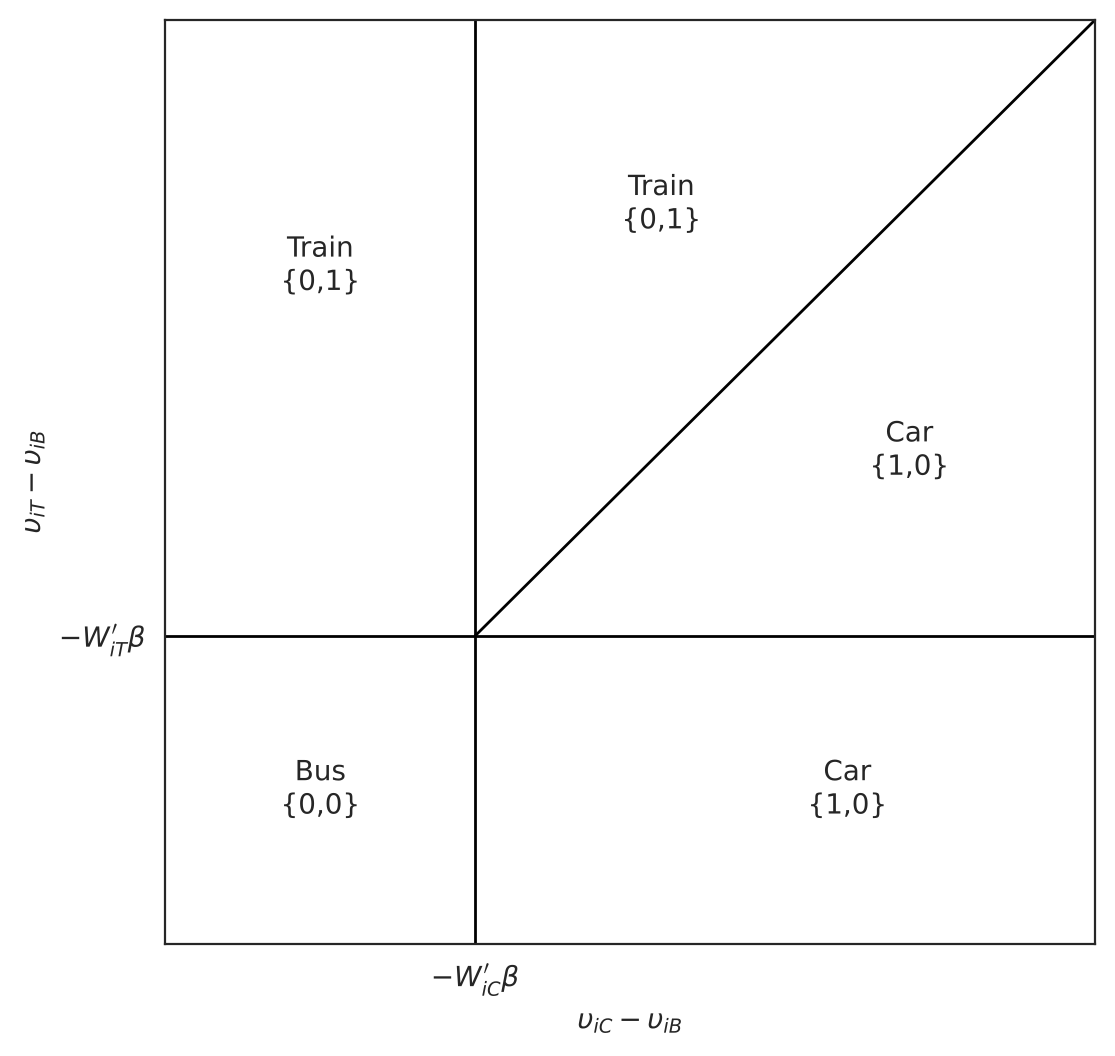

In [31]:
# the figure of the book: the choice for each value of the two unobserved terms
# the two thresholds are drawn at 1, it could be any other value
plt.figure(figsize=(6,6))

# on the right of the vertical line, car is better than bus
plt.plot([1, 1], [0, 3], color='k', linewidth=1)
# above the horizontal line, train is better than bus
plt.plot([0, 3], [1, 1], color='k', linewidth=1)
# below the diagonal line, car is better than train
plt.plot([1, 3], [1, 3], color='k', linewidth=1)

# the choice in each area: {car, train}
plt.text(0.5, 0.5, 'Bus\n{0,0}', ha='center', va='center')
plt.text(2.2, 0.5, 'Car\n{1,0}', ha='center', va='center')
plt.text(2.4, 1.6, 'Car\n{1,0}', ha='center', va='center')
plt.text(0.5, 2.2, 'Train\n{0,1}', ha='center', va='center')
plt.text(1.6, 2.4, 'Train\n{0,1}', ha='center', va='center')

# the names of the thresholds are written in LaTeX
plt.xticks([1], [r"$-W_{iC}'\beta$"])
plt.yticks([1], [r"$-W_{iT}'\beta$"])
plt.xlabel(r"$\upsilon_{iC} - \upsilon_{iB}$")
plt.ylabel(r"$\upsilon_{iT} - \upsilon_{iB}$")
plt.xlim(0, 3)
plt.ylim(0, 3)
plt.show()

## 5.6.3 Multinomial Probit in Python

In [32]:
def f_biprobit(para, Y, W1, W2, K=10):
    """
    Minus the log likelihood of the bivariate probit (three choices)
    * para: the correlation parameter first, then the betas
    * Y: two columns, 1 in the first if choice 1 is chosen,
      1 in the second if choice 2 is chosen
    * W1, W2: characteristics of choice 1 and of choice 2
    * K is a counter for the number of draws from the normal
      distribution - more draws gives greater accuracy
      but slower computational times.
    """

    # function setup
    np.random.seed(123456789)  # helps the optimizer work better.
    eps = 1e-20  # used below to make sure the logs work.
    N = Y.shape[0]  # number of rows of Y
    W1 = np.c_[np.ones(N), W1]
    W2 = np.c_[np.ones(N), W2]
    J = W1.shape[1]
    rho = np.exp(para[0])/(1 + np.exp(para[0]))
    # the "sigmoid" function that keeps value between 0 and 1.
    # It assumes that the correlation is positive.
    beta = para[1:(J+1)]

    # integration to find the probabilities
    u = np.random.normal(size=K)
    p_00 = np.zeros(N)
    p_10 = np.zeros(N)
    for uk in u:
        uk0 = uk < -W1.dot(beta)
        p_00 = p_00 + uk0*stats.norm.cdf((-W2.dot(beta) - rho*uk)/((1 - rho**2)**0.5))
        p_10 = p_10 + (1 - uk0)*stats.norm.cdf(((W1 - W2).dot(beta) +
                                                (1 - rho)*uk)/((1 - rho**2)**0.5))

    # determine the likelihood
    # in Python each condition goes inside brackets when we use &
    log_lik = (((Y[:,0]==0) & (Y[:,1]==0))*np.log(p_00/K + eps) +
               ((Y[:,0]==1) & (Y[:,1]==0))*np.log(p_10/K + eps) +
               ((Y[:,0]==0) & (Y[:,1]==1))*np.log(1 - p_00/K - p_10/K + eps))
    return -np.sum(log_lik)

## 5.6.5 Multinomial Logit in Python

In [33]:
def f_logit(beta, Y, W1, W2):
    """
    Minus the log likelihood of the multinomial logit (three choices)
    * same Y, W1 and W2 as in f_biprobit
    """
    eps = 1e-20  # so we don't take log of zero.
    N = Y.shape[0]
    W1 = np.c_[np.ones(N), W1]
    W2 = np.c_[np.ones(N), W2]
    p_10 = np.exp(W1.dot(beta))/(1 + np.exp(W1.dot(beta)) + np.exp(W2.dot(beta)))
    p_01 = np.exp(W2.dot(beta))/(1 + np.exp(W1.dot(beta)) + np.exp(W2.dot(beta)))
    p_00 = 1 - p_10 - p_01
    log_lik = (((Y[:,0]==0) & (Y[:,1]==0))*np.log(p_00 + eps) +
               ((Y[:,0]==1) & (Y[:,1]==0))*np.log(p_10 + eps) +
               ((Y[:,0]==0) & (Y[:,1]==1))*np.log(p_01 + eps))
    return -np.sum(log_lik)

## 5.6.6 Simulating Multinomial Choice

In [34]:
# the book loads the mvtnorm package to create multivariate normal distributions
# numpy has np.random.multivariate_normal for this (rmvnorm in R)
np.random.seed(123456789)

N = 1000
mu = np.array([0, 0])
rho = 0.1 # correlation parameter
Sig = np.array([[1, rho], [rho, 1]])

# relative unobserved characteristics of two choices
u = np.random.multivariate_normal(mu, Sig, size=N)

# relative observed characteristics of two choices.
x1 = np.random.rand(N, 2)
x2 = np.random.rand(N, 2)

a = -1
b = -3
c = 4
U = a + b*x1 + c*x2 + u

# a choice is chosen if its utility is above 0 (the left out choice)
# and above the utility of the other choice
# column 0 is the first choice and column 1 is the second choice
Y = np.zeros((N, 2))
Y[:,0] = (U[:,0] > 0) & (U[:,0] > U[:,1])
Y[:,1] = (U[:,1] > 0) & (U[:,1] > U[:,0])

In [35]:
# the two characteristics of each choice, side by side (cbind in R)
W1 = np.c_[x1[:,0], x2[:,0]]
W2 = np.c_[x1[:,1], x2[:,1]]

# bivariate probit, with 100 draws
# we start at the true values
# maxit in R is maxiter in Python
par1 = [np.log(rho), a, b, c]
a1 = minimize(f_biprobit, x0=par1, args=(Y, W1, W2, 100),
              method='Nelder-Mead', options={'maxiter': 1000})

# multinomial logit
par2 = [a, b, c]
b1 = minimize(f_logit, x0=par2, args=(Y, W1, W2),
              method='Nelder-Mead', options={'maxiter': 1000})

In [36]:
# bivariate probit estimates of a, b and c
# the true values are -1, -3 and 4
# position 0 is the correlation parameter, so we take positions 1 to 3
a1.x[1:4]

array([-0.99213005, -3.09035252,  3.98056493])

In [37]:
# logit estimates of a, b and c
b1.x[0:3]

array([-1.34491709, -5.46208092,  6.7485137 ])

## 5.7.1 National Household Travel Survey

In [38]:
# household file of the National Household Travel Survey 2017
# as.is of R is not needed in Python
x = pd.read_csv('../data/hhpub.csv')

In [39]:
# We define a bunch of functions to clean the data
# in an organised fashion

def create_choice_vars(df):
    """
    We create the "choice" variables for transportation use:
    * choice: 'car', 'bus' or 'train', the mode used every day (code 1)
    * car1 and train1: 1 if the choice is car (train), 0 if not
    """
    # the choice is missing if no mode is used every day
    df['choice'] = None
    df.loc[df['CAR']==1, 'choice'] = 'car'
    df.loc[df['BUS']==1, 'choice'] = 'bus'
    df.loc[df['TRAIN']==1, 'choice'] = 'train'
    # each line overrules the previous choice.

    # in R a comparison with a missing value gives a missing value
    # in Python it gives False, so we put the missing values back with np.where
    df['car1'] = np.where(df['choice'].isna(), np.nan, df['choice']=='car')
    df['train1'] = np.where(df['choice'].isna(), np.nan, df['choice']=='train')
    return df

def create_home_var(df):
    # home ownership
    # 1 for the owners, 0 for the codes above 1, missing for the negative codes
    df['home'] = np.where(df['HOMEOWN']==1, 1, np.nan)
    df['home'] = np.where(df['HOMEOWN']>1, 0, df['home'])
    return df

def create_income_var(df):
    # household income
    # the negative codes are missing values
    df['income'] = np.where(df['HHFAMINC']>0, df['HHFAMINC'], np.nan)
    return df

def create_density_var(df):
    # population density
    # missing is -9.
    # dividing by 1000 makes the reported results look nicer.
    df['density'] = np.where(df['HTPPOPDN']==-9, np.nan, df['HTPPOPDN'])/1000
    return df

def create_urban_var(df):
    # urban versus rural
    # the book keeps True/False here
    # statsmodels puts the True/False variables first in its list of coefficients
    # and we need the coefficients in the order of the formula in section 5.7.3
    # so we code urban1 in 0/1s
    df['urban1'] = (df['URBAN']==1).astype(int)
    return df

In [40]:
def keep_commuters_in_cities(df):
    """
    We limit to:
    * households that may commute (at least one worker)
    * and those that live in some type of city (MSACAT 1 or 2)
    """
    condition1 = df['WRKCOUNT']>0
    condition2 = (df['MSACAT']==1) | (df['MSACAT']==2)
    return df[condition1 & condition2]

def create_rail_var(df):
    # an MSA with rail
    df['rail'] = df['RAIL']==1
    return df

def drop_missing(df):
    # we drop the households with a missing value in one of these variables
    cols = ['car1', 'train1', 'home', 'HHSIZE', 'income',
            'urban1', 'density', 'MSACAT', 'rail']
    return df.dropna(subset=cols)

In [41]:
# and we perform the data cleaning using the .pipe operator
# on the original dataset x

x = (
    x
    .pipe(create_choice_vars)
    .pipe(create_home_var)
    .pipe(create_income_var)
    .pipe(create_density_var)
    .pipe(create_urban_var)
)

# y is the sample we work with (the book calls it y, it is not an outcome)
y = (
    x
    .pipe(keep_commuters_in_cities)
    .pipe(create_rail_var)
    .pipe(drop_missing)
)

In [42]:
# number of households left
print(len(y))

34043


In [43]:
# vars is already the name of a Python function, so we take another name
var_names = ['car1', 'train1', 'home', 'HHSIZE', 'income',
             'urban1', 'density']

# mean of each variable for the two types of cities
# rail is True or False, and True is equal to 1 in Python
summ_tab = pd.DataFrame()
summ_tab['Rail'] = y[y['rail']==1][var_names].mean()
summ_tab['No Rail'] = y[y['rail']==0][var_names].mean()
summ_tab

,Rail,No Rail
car1,0.877925,0.973861
train1,0.096610,0.010036
home,0.730127,0.749231
HHSIZE,2.487870,2.462420
income,7.518840,7.054552
urban1,0.910272,0.869753
density,7.559076,4.661936


## 5.7.2 Demand for Cars

In [44]:
# Without Rail
y_nr = y[y['rail']==0]
glm_nr = sm.logit(formula="car1 ~ home + HHSIZE + income + urban1 + density",
                  data=y_nr).fit(disp=0)

# With Rail
y_r = y[y['rail']==1]
glm_r = sm.logit(formula="car1 ~ home + HHSIZE + income + urban1 + density",
                 data=y_r).fit(disp=0)

In [45]:
# (1) is demand in cities without a dense rail network
# (2) is demand in cities with a rail network
print(summary_col([glm_nr,glm_r],
                  stars=True,
                  float_format='%0.3f',
                  model_names=['(1)','(2)'],
                  info_dict=info
            ))


             (1)       (2)   
-----------------------------
Intercept 3.775***  3.506*** 
          (0.270)   (0.211)  
home      0.633***  0.498*** 
          (0.095)   (0.071)  
HHSIZE    -0.018    0.050*   
          (0.033)   (0.026)  
income    0.133***  -0.068***
          (0.019)   (0.013)  
urban1    -1.160*** -0.312*  
          (0.246)   (0.187)  
density   -0.055*** -0.109***
          (0.008)   (0.003)  
AIC       5129.3    7005.1   
BIC       5177.5    7049.2   
Log.Lik.  -2558.673 -3496.533
N         22419     11624    
RMSE      0.16      0.29     
Standard errors in
parentheses.
* p<.1, ** p<.05, ***p<.01


## 5.7.3 Estimating Demand for Rail

In [46]:
# number of households in cities with rail
N_r = len(y_r)

# characteristics of car
# the last column is for density, which is 0 for car
# R repeats a single 0 down the column, numpy needs a full column of 0's
X_r_car = np.c_[y_r['home'], y_r['HHSIZE'], y_r['income'],
                y_r['urban1'], np.zeros(N_r)]

# train value is assumed to be determined by
# population density.
# four columns of 0's and then density
X_r_train = np.c_[np.zeros((N_r, 4)), y_r['density']]

# first column: the choice is car, second column: the choice is train
Y1_r = np.c_[y_r['choice']=='car', y_r['choice']=='train']

In [47]:
# bivariate probit
# starting values: 0 for the correlation parameter (c(0, ...) in R is np.append),
# and the logit estimates of the previous section for beta
# these estimates are in the order of the formula: intercept, home, HHSIZE,
# income, urban1 and density, which is the order of the columns of our matrices
# with 100 draws and more than 11000 households, this step takes about two minutes
par1 = np.append(0, glm_r.params)
a1 = minimize(f_biprobit, x0=par1, args=(Y1_r, X_r_car, X_r_train, 100),
              method='Nelder-Mead', options={'maxiter': 10000})

In [48]:
# multinomial logit
par2 = glm_r.params
a2 = minimize(f_logit, x0=par2, args=(Y1_r, X_r_car, X_r_train),
              method='Nelder-Mead', options={'maxiter': 10000})

In [49]:
# the estimates (the book does not print them)
# intercept, home, HHSIZE, income, urban1 and density
est_tab = pd.DataFrame()
est_tab['Probit'] = a1.x[1:7]
est_tab['Logit'] = a2.x
est_tab.index = ['intercept', 'home', 'HHSIZE', 'income', 'urban1', 'density']
est_tab

,Probit,Logit
intercept,-0.315918,0.610193
home,0.815946,0.878112
HHSIZE,0.197788,0.267324
income,-0.072902,0.073668
urban1,1.088942,1.373508
density,0.025046,0.084833


## 5.7.4 Predicting Demand for Rail

In [50]:
# number of households in cities without rail
N_nr = len(y_nr)

# same matrices as before for the cities without rail
# this time the column of 1's is added by hand
X_nr_car = np.c_[np.ones(N_nr), y_nr['home'], y_nr['HHSIZE'], y_nr['income'],
                 y_nr['urban1'], np.zeros(N_nr)]
X_nr_train = np.c_[np.ones(N_nr), np.zeros((N_nr, 4)), y_nr['density']]

In [51]:
# Probit estimate
np.random.seed(123456789)

rho = np.exp(a1.x[0])/(1 + np.exp(a1.x[0]))
beta = a1.x[1:len(a1.x)]
W1 = X_nr_car
W2 = X_nr_train
K1 = 100
u1 = np.random.normal(size=K1)

# same loop as in f_biprobit
p_00 = np.zeros(N_nr)
p_10 = np.zeros(N_nr)
for uk in u1:
    uk0 = uk < -W1.dot(beta)
    p_00 = p_00 + uk0*stats.norm.cdf((-W2.dot(beta) - rho*uk)/((1 - rho**2)**0.5))
    p_10 = p_10 + (1 - uk0)*stats.norm.cdf(((W1 - W2).dot(beta) +
                                            (1 - rho)*uk)/((1 - rho**2)**0.5))

# the probability of train is what is left after bus and car
p_train_pr = (K1 - p_00 - p_10)/K1
print(np.mean(p_train_pr))

0.07712062885025356


In [52]:
# Logit estimate
p_train_lg_top = np.exp(X_nr_train.dot(a2.x))
p_train_lg_bottom = 1 + np.exp(X_nr_car.dot(a2.x)) + np.exp(X_nr_train.dot(a2.x))
p_train_lg = p_train_lg_top/p_train_lg_bottom
print(np.mean(p_train_lg))

0.08302668552436952
